=== Параметры задачи ===
R     = 0.0025 м
a     = 7.6923e-06 м²/с
Bi    = 0.083333

=== Первые 10 корней mu_n и коэффициентов A_n ===
  n           mu_n       J0(mu_n)            A_n
  1     0.40403269 9.59603890e-01 1.02054165e+00
  2     3.85338958 -4.02664893e-01 -2.78622434e-02
  3     7.02745439 3.00094630e-01 1.12443250e-02
  4    10.18165590 -2.49696509e-01 -6.43828735e-03
  5    13.32994491 2.18355139e-01 4.29547949e-03
  6    16.47568874 -1.96462858e-01 -3.12514393e-03
  7    19.62010629 1.80061751e-01 2.40445545e-03
  8    22.76374545 -1.67183480e-01 -1.92380977e-03
  9    25.90688892 1.56724175e-01 1.58444707e-03
 10    29.04969732 -1.48010501e-01 -1.33434897e-03

=== Число членов ряда для eps_theta = 1e-5 ===
      Fo   n_членов       theta(0)       theta(1)
   0.001         21 1.00000276e+00 9.96978567e-01
   0.005         11 1.00000151e+00 9.93166241e-01
   0.010          9 1.00000026e+00 9.90227371e-01
   0.020          7 1.00000003e+00 9.85948621e-01
   0.050          5

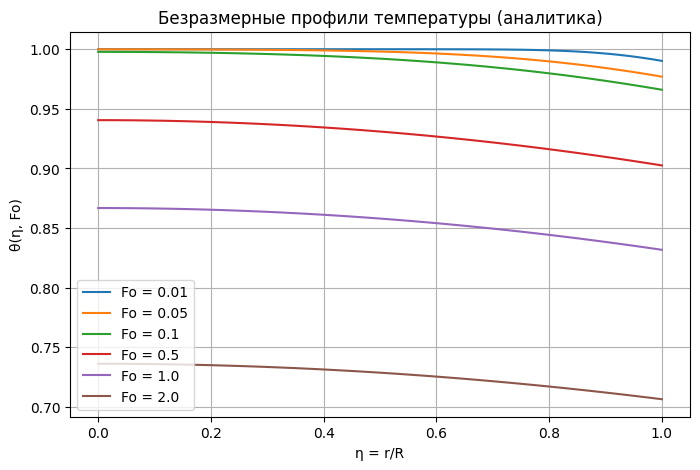

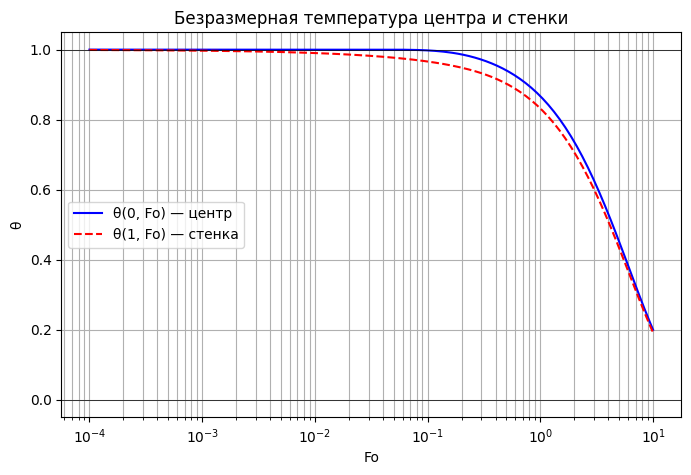

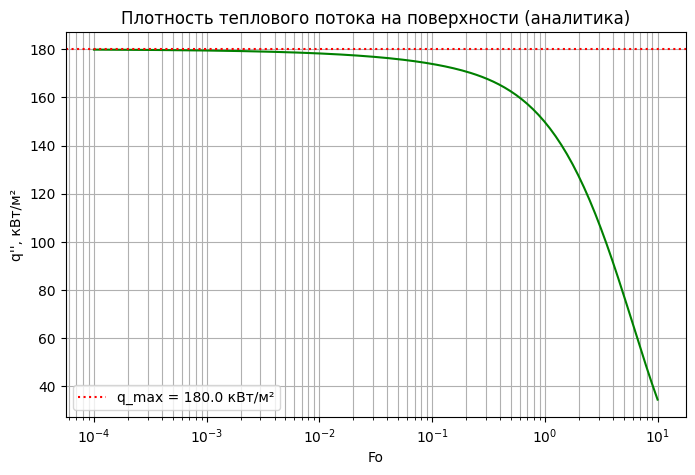

q''(Fo=1e-6) = 179.97 кВт/м²  (должно быть ~180)
q''(Fo=10)   = 34.454 кВт/м²  (должно быть ~0)
q''(Fo=10)   = 34.454 кВт/м²
q''(Fo=50)   = 0.0503 кВт/м²
q''(Fo=100)  = 0.000014 кВт/м²
q''(Fo=1000) = 2.243e-69 кВт/м²


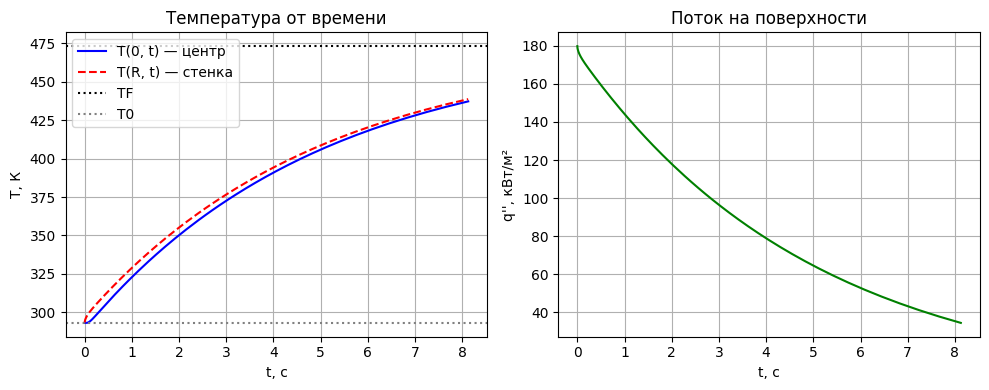

theta_k.shape = (501, 21)
Fo_k[:3] = [0.        0.1241043 0.2471812]
Сохранено: theta_compare.png
Сохранено: theta_center_wall_compare.png

=== Сравнение θ с аналитикой (Fo, θ_центр, ε_центр, θ_стенка, ε_стенка) ===
        Fo      θ_c_num       θ_c_an        ε_c      θ_w_num       θ_w_an        ε_w
0.0000e+00     1.000000     0.999981   1.88e-05     1.000000     0.999831   1.69e-04
3.2010e+00     0.605243     0.605192   8.51e-05     0.580792     0.580744   8.25e-05
6.4010e+00     0.358990     0.358945   1.25e-04     0.344487     0.344445   1.23e-04
9.6010e+00     0.212929     0.212894   1.65e-04     0.204327     0.204294   1.62e-04
1.2924e+01     0.123783     0.123758   2.06e-04     0.118783     0.118759   2.03e-04
1.6124e+01     0.073420     0.073402   2.46e-04     0.070454     0.070437   2.43e-04
1.9324e+01     0.043548     0.043535   2.85e-04     0.041789     0.041777   2.83e-04
2.2647e+01     0.025316     0.025308   3.27e-04     0.024293     0.024285   3.25e-04
2.5847e+01     0.01

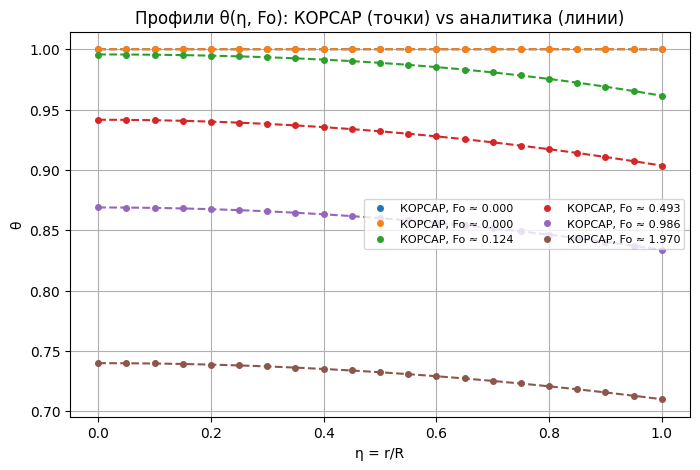

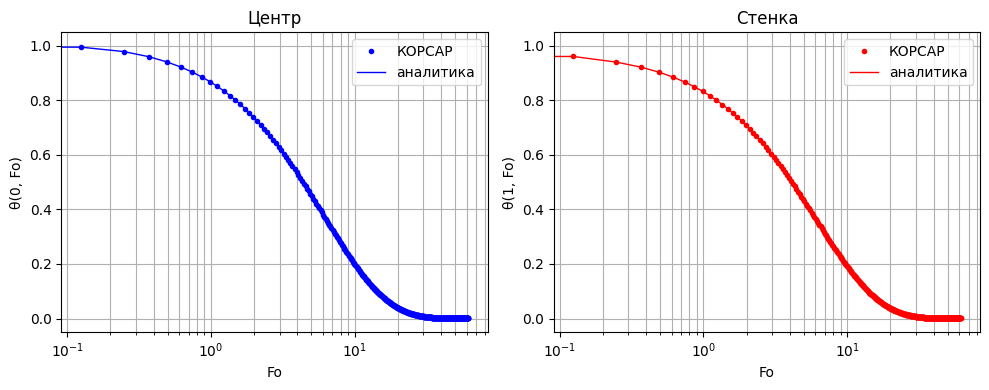

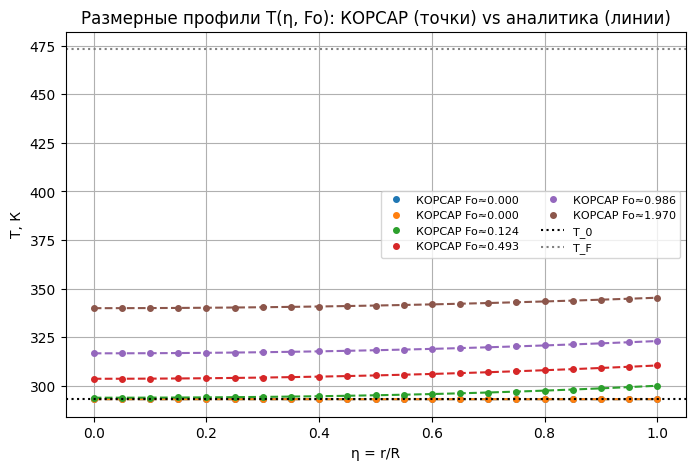

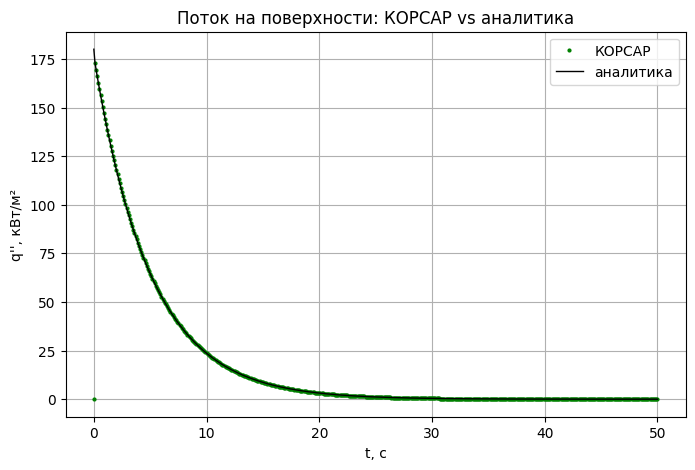

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0, j1
from scipy.optimize import brentq
import os

# В Colab графики показываются в ноутбуке
%matplotlib inline

# ============================================================
# 1. Исходные данные
# ============================================================
R      = 0.0025
LAM    = 30.0
RHO    = 7800.0
C      = 500.0
A_DIF  = LAM/(RHO*C)
ALPHA  = 1000.0
T0     = 293.15
TF     = 473.15
BI     = ALPHA*R/LAM

print(f"=== Параметры задачи ===")
print(f"R     = {R} м")
print(f"a     = {A_DIF:.4e} м²/с")
print(f"Bi    = {BI:.6f}")

# ============================================================
# 2. Корни mu_n J1(mu) = Bi J0(mu)
# ============================================================
def find_mu_roots(Bi, N=100):
    roots = []
    for n in range(1, N+1):
        def f(m): return m*j1(m) - Bi*j0(m)
        lo = 1e-8 if n==1 else roots[-1] + 0.1
        hi = lo + np.pi
        for _ in range(50):
            if f(lo)*f(hi) < 0: break
            hi += np.pi
        mu = brentq(f, lo, hi, xtol=1e-14, rtol=1e-14)
        roots.append(mu)
    return np.array(roots)

MU = find_mu_roots(BI, N=100)
A  = 2.0*BI / ((MU**2 + BI**2)*j0(MU))

print(f"\n=== Первые 10 корней mu_n и коэффициентов A_n ===")
print(f"{'n':>3} {'mu_n':>14} {'J0(mu_n)':>14} {'A_n':>14}")
for n in range(10):
    print(f"{n+1:>3} {MU[n]:>14.8f} {j0(MU[n]):>14.8e} {A[n]:>14.8e}")

# ============================================================
# 3. Аналитическое решение
# ============================================================
def theta_analytic(eta, Fo, tol=1e-12, Nmax=None):
    eta = np.atleast_1d(eta).astype(float)
    theta = np.zeros_like(eta)
    if Nmax is None: Nmax = len(MU)
    n_used = 0
    for n in range(Nmax):
        term = A[n] * j0(MU[n]*eta) * np.exp(-MU[n]**2 * Fo)
        theta += term
        n_used = n+1
        if np.max(np.abs(term)) < tol: break
    return theta, n_used

def theta_wall(Fo, tol=1e-12):
    return theta_analytic(np.array([1.0]), Fo, tol)[0][0]

def theta_center(Fo, tol=1e-12):
    return theta_analytic(np.array([0.0]), Fo, tol)[0][0]

def q_surface(Fo, tol=1e-12):
    th_w = theta_wall(Fo, tol)
    return ALPHA * (TF - T0) * th_w   

# ============================================================
# 4. Число членов ряда для eps = 1e-5
# ============================================================
print(f"\n=== Число членов ряда для eps_theta = 1e-5 ===")
print(f"{'Fo':>8} {'n_членов':>10} {'theta(0)':>14} {'theta(1)':>14}")
for Fo in [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]:
    th_c, n_c = theta_analytic(np.array([0.0]), Fo, tol=1e-5)
    th_w, _   = theta_analytic(np.array([1.0]), Fo, tol=1e-5)
    print(f"{Fo:>8.3f} {n_c:>10} {th_c[0]:>14.8e} {th_w[0]:>14.8e}")

# ============================================================
# 5. Профили theta(eta, Fo) — аналитика
# ============================================================
eta = np.linspace(0, 1, 101)
Fo_list = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]

plt.figure(figsize=(8, 5))
for Fo in Fo_list:
    th, _ = theta_analytic(eta, Fo, tol=1e-10)
    plt.plot(eta, th, label=f'Fo = {Fo}')
plt.xlabel('η = r/R'); plt.ylabel('θ(η, Fo)')
plt.title('Безразмерные профили температуры (аналитика)')
plt.legend(); plt.grid(True)
plt.savefig('theta_analytic.png', dpi=150)
plt.show()       # <-- Colab покажет график в ноутбуке

# ============================================================
# 6. theta(0, Fo), theta(1, Fo)
# ============================================================
Fo_arr   = np.logspace(-4, 1, 200)
th_c_arr = np.array([theta_center(Fo, tol=1e-12) for Fo in Fo_arr])
th_w_arr = np.array([theta_wall(Fo,   tol=1e-12) for Fo in Fo_arr])

plt.figure(figsize=(8, 5))
plt.semilogx(Fo_arr, th_c_arr, 'b-',  label='θ(0, Fo) — центр')
plt.semilogx(Fo_arr, th_w_arr, 'r--', label='θ(1, Fo) — стенка')
plt.axhline(0, color='k', lw=0.5)
plt.axhline(1, color='k', lw=0.5)
plt.xlabel('Fo'); plt.ylabel('θ')
plt.title('Безразмерная температура центра и стенки')
plt.legend(); plt.grid(True, which='both')
plt.savefig('theta_center_wall.png', dpi=150)
plt.show()

# ============================================================
# 7. q''(Fo)
# ============================================================
q_arr = np.array([q_surface(Fo, tol=1e-12) for Fo in Fo_arr])

plt.figure(figsize=(8, 5))
plt.semilogx(Fo_arr, q_arr/1e3, 'g-')
plt.axhline(ALPHA*(TF-T0)/1e3, color='r', ls=':',
            label=f'q_max = {ALPHA*(TF-T0)/1e3:.1f} кВт/м²')
plt.xlabel('Fo'); plt.ylabel("q'', кВт/м²")
plt.title('Плотность теплового потока на поверхности (аналитика)')
plt.legend(); plt.grid(True, which='both')
plt.savefig('q_analytic.png', dpi=150)
plt.show()
print(f"q''(Fo=1e-6) = {q_surface(1e-6)/1e3:.2f} кВт/м²")
print(f"q''(Fo=10)   = {q_surface(10.0)/1e3:.3f} кВт/м²")
print(f"q''(Fo=10)   = {q_surface(10.0)/1e3:.3f} кВт/м²")
print(f"q''(Fo=50)   = {q_surface(50.0)/1e3:.4f} кВт/м²")
print(f"q''(Fo=100)  = {q_surface(100.0)/1e3:.6f} кВт/м²")
print(f"q''(Fo=1000) = {q_surface(1000.0)/1e3:.3e} кВт/м²")
# ============================================================
# 8. Размерные T_C(t), T_W(t), q(t)
# ============================================================
t_arr = Fo_arr * R**2 / A_DIF
T_C_an = TF + (T0 - TF)*th_c_arr
T_W_an = TF + (T0 - TF)*th_w_arr

plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.plot(t_arr, T_C_an, 'b-',  label='T(0, t) — центр')
plt.plot(t_arr, T_W_an, 'r--', label='T(R, t) — стенка')
plt.axhline(TF, color='k', ls=':', label='TF')
plt.axhline(T0, color='gray', ls=':', label='T0')
plt.xlabel('t, с'); plt.ylabel('T, К')
plt.legend(); plt.grid(True)
plt.title('Температура от времени')

plt.subplot(1,2,2)
plt.plot(t_arr, q_arr/1e3, 'g-')
plt.xlabel('t, с'); plt.ylabel("q'', кВт/м²")
plt.grid(True)
plt.title("Поток на поверхности")
plt.tight_layout()
plt.savefig('temp_flux_time.png', dpi=150)
plt.show()

# ============================================================
# 9. Сравнение с КОРСАР
# ============================================================

def load_korsar_theta(fname, n_cols=23):
    with open(fname, 'r') as f:
        lines = [l.rstrip('\n') for l in f if l.strip()]
    all_tokens = []
    for l in lines[1:]:
        all_tokens.extend(l.split())
    n_rows = len(all_tokens) // n_cols
    data = np.array(all_tokens[:n_rows*n_cols], dtype=float).reshape(n_rows, n_cols)
    return data[:,0], data[:,1], data[:,2:23]

def load_korsar_q(fname, n_cols=5):
    with open(fname, 'r') as f:
        lines = [l.rstrip('\n') for l in f if l.strip()]
    all_tokens = []
    for l in lines[1:]:
        all_tokens.extend(l.split())
    n_rows = len(all_tokens) // n_cols
    data = np.array(all_tokens[:n_rows*n_cols], dtype=float).reshape(n_rows, n_cols)
    return data[:,0], data[:,1], data[:,2], data[:,3], data[:,4]

# --- вызовы ---
if os.path.exists('RESULT_THETA_step.DAT'):
    tau_k, Fo_k, theta_k = load_korsar_theta('RESULT_THETA_step.DAT')
    print("theta_k.shape =", theta_k.shape)   # (N, 21)
    print("Fo_k[:3] =", Fo_k[:3])

    # Профили: берём 5-6 моментов Fo из КОРСАР
    Fo_list_num = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]
    plt.figure(figsize=(8, 5))
    for Fo in Fo_list_num:
        i = np.argmin(np.abs(Fo_k - Fo))
        eta_k = np.linspace(0, 1, 21)
        plt.plot(eta_k, theta_k[i, :], 'o', ms=4,
                 label=f'КОРСАР, Fo ≈ {Fo_k[i]:.3f}')
        th_an, _ = theta_analytic(eta_k, Fo_k[i], tol=1e-12)
        plt.plot(eta_k, th_an, '--', color=plt.gca().lines[-1].get_color())
    plt.xlabel('η = r/R')
    plt.ylabel('θ')
    plt.title('Профили θ(η, Fo): КОРСАР (точки) vs аналитика (линии)')
    plt.legend(fontsize=8, ncol=2)
    plt.grid(True)
    plt.savefig('theta_compare.png', dpi=150)
    print("Сохранено: theta_compare.png")

    # theta(0, Fo) и theta(1, Fo)
    th_c_num = theta_k[:, 0]
    th_w_num = theta_k[:, -1]
    th_c_an  = np.array([theta_center(Fo, tol=1e-12) for Fo in Fo_k])
    th_w_an  = np.array([theta_wall(Fo,   tol=1e-12) for Fo in Fo_k])

    plt.figure(figsize=(10, 4))
    plt.subplot(1,2,1)
    plt.semilogx(Fo_k, th_c_num, 'b.', label='КОРСАР')
    plt.semilogx(Fo_k, th_c_an, 'b-', lw=1, label='аналитика')
    plt.xlabel('Fo'); plt.ylabel('θ(0, Fo)')
    plt.title('Центр')
    plt.legend(); plt.grid(True, which='both')

    plt.subplot(1,2,2)
    plt.semilogx(Fo_k, th_w_num, 'r.', label='КОРСАР')
    plt.semilogx(Fo_k, th_w_an, 'r-', lw=1, label='аналитика')
    plt.xlabel('Fo'); plt.ylabel('θ(1, Fo)')
    plt.title('Стенка')
    plt.legend(); plt.grid(True, which='both')
    plt.tight_layout()
    plt.savefig('theta_center_wall_compare.png', dpi=150)
    print("Сохранено: theta_center_wall_compare.png")

    # Ошибка
    eps_c = np.abs(th_c_num - th_c_an) / np.maximum(np.abs(th_c_an), 1e-12)
    eps_w = np.abs(th_w_num - th_w_an) / np.maximum(np.abs(th_w_an), 1e-12)

    # Таблица
    print("\n=== Сравнение θ с аналитикой (Fo, θ_центр, ε_центр, θ_стенка, ε_стенка) ===")
    print(f"{'Fo':>10} {'θ_c_num':>12} {'θ_c_an':>12} {'ε_c':>10} "
          f"{'θ_w_num':>12} {'θ_w_an':>12} {'ε_w':>10}")
    # Прореживаем: не более 20 строк
    idx = np.linspace(0, len(Fo_k)-1, min(20, len(Fo_k))).astype(int)
    for i in idx:
        print(f"{Fo_k[i]:>10.4e} {th_c_num[i]:>12.6f} {th_c_an[i]:>12.6f} "
              f"{eps_c[i]:>10.2e} {th_w_num[i]:>12.6f} {th_w_an[i]:>12.6f} "
              f"{eps_w[i]:>10.2e}")
    print(f"\nМаксимальная ошибка по центру: {eps_c.max():.3e}")
    print(f"Максимальная ошибка по стенке: {eps_w.max():.3e}")
else:
    print("\nRESULT_THETA_step.DAT не найден — сравнение с КОРСАР пропущено")

# --- размерные T (КОРСАР vs аналитика) ---
def load_korsar_T(fname, n_cols=23):
    """Загрузка файла, где длинные строки разбиты на 14 + 9 чисел."""
    with open(fname, 'r') as f:
        lines = [l.rstrip('\n') for l in f if l.strip()]
    all_tokens = []
    for l in lines[1:]:  # пропускаем заголовок
        all_tokens.extend(l.split())
    n_rows = len(all_tokens) // n_cols
    data = np.array(all_tokens[:n_rows*n_cols], dtype=float).reshape(n_rows, n_cols)
    return data[:, 0], data[:, 1:22], data[:, 22]

if os.path.exists('RESULT_T_step.DAT'):
    tau_T, T_num, T_wall_num = load_korsar_T('RESULT_T_step.DAT')
    print(f"RESULT_T_step.DAT: shape = ({len(tau_T)}, 21)")

    # --- ВОТ ЗДЕСЬ ВЫЧИСЛЯЕТСЯ Fo_T ---
    Fo_T = tau_T * A_DIF / R**2
    eta = np.linspace(0, 1, 21)

    # Профили в контрольных Fo
    Fo_list_T = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]

    plt.figure(figsize=(8, 5))
    for Fo in Fo_list_T:
        i = np.argmin(np.abs(Fo_T - Fo))
        T_num_i = T_num[i, :]
        T_an_i = TF + (T0 - TF) * theta_analytic(eta, Fo_T[i], tol=1e-12)[0]
        plt.plot(eta, T_num_i, 'o', ms=4, label=f'КОРСАР Fo≈{Fo_T[i]:.3f}')
        plt.plot(eta, T_an_i, '--', color=plt.gca().lines[-1].get_color())

    plt.axhline(T0, color='k', ls=':', label='T_0')
    plt.axhline(TF, color='gray', ls=':', label='T_F')
    plt.xlabel('η = r/R'); plt.ylabel('T, К')
    plt.title('Размерные профили T(η, Fo): КОРСАР (точки) vs аналитика (линии)')
    plt.legend(fontsize=8, ncol=2); plt.grid(True)
    plt.savefig('T_compare.png', dpi=150)
    print("Сохранено: T_compare.png")

    # Ошибка
    eps_T = []
    print(f"\n=== Ошибка T(η, Fo) ===")
    print(f"{'Fo':>8} {'max|T_num - T_an|, K':>22} {'eps_T (отн. dT)':>15}")
    for Fo in Fo_list_T:
        i = np.argmin(np.abs(Fo_T - Fo))
        T_num_i = T_num[i, :]
        T_an_i = TF + (T0 - TF) * theta_analytic(eta, Fo_T[i], tol=1e-12)[0]
        dT = np.max(np.abs(T_num_i - T_an_i))
        eps = dT / (TF - T0)
        eps_T.append(eps)
        print(f"{Fo_T[i]:>8.3f} {dT:>22.6f} {eps:>15.3e}")
    print(f"Макс. eps_T = {max(eps_T):.3e}")
else:
    print("RESULT_T_step.DAT не найден")

# --- поток ---
if os.path.exists('RESULT_Q_step.DAT'):
    tau_q, T_W_k, q_num, q_lin_k, E_acc_k = load_korsar_q('RESULT_Q_step.DAT')

    # Восстанавливаем Fo по времени
    Fo_q = tau_q * A_DIF / R**2
    q_an = np.array([q_surface(Fo, tol=1e-12) for Fo in Fo_q])

    plt.figure(figsize=(8, 5))
    plt.plot(tau_q, q_num/1e3, 'g.', ms=4, label='КОРСАР')
    plt.plot(tau_q, q_an/1e3, 'k-', lw=1, label='аналитика')
    plt.xlabel('t, с')
    plt.ylabel("q'', кВт/м²")
    plt.title("Поток на поверхности: КОРСАР vs аналитика")
    plt.legend()
    plt.grid(True)
    plt.savefig('q_compare.png', dpi=150)
    print("Сохранено: q_compare.png")

    # Ошибка (исключаем t=0 — артефакт инициализации)
    mask_q = tau_q > 1e-6
    eps_q = np.abs(q_num[mask_q] - q_an[mask_q]) / np.maximum(np.abs(q_an[mask_q]), 1.0)
    print(f"\n=== Поток q'': макс. относительная ошибка (без t=0) = {eps_q.max():.3e} ===")

    # Таблица (только для t > 0)
    tau_valid  = tau_q[mask_q]
    q_num_valid = q_num[mask_q]
    q_an_valid  = q_an[mask_q]
    eps_q_valid = eps_q

    print(f"{'t, с':>10} {'q_num, кВт/м²':>16} {'q_an, кВт/м²':>16} {'ε_q':>10}")
    idx = np.linspace(0, len(tau_valid)-1, min(20, len(tau_valid))).astype(int)
    for i in idx:
        print(f"{tau_valid[i]:>10.4f} {q_num_valid[i]/1e3:>16.4f} "
              f"{q_an_valid[i]/1e3:>16.4f} {eps_q_valid[i]:>10.2e}")
else:
    print("\nRESULT_Q_step.DAT не найден — сравнение по потоку пропущено")

# ============================================================
# 10. CSV для отчёта
# ============================================================
eta_export = np.linspace(0, 1, 101)
with open('analytic_theta_profiles.csv', 'w') as f:
    f.write('eta,' + ','.join([f'Fo={Fo}' for Fo in Fo_list]) + '\n')
    for e in eta_export:
        row = [f'{e:.6f}']
        for Fo in Fo_list:
            th, _ = theta_analytic(np.array([e]), Fo, tol=1e-12)
            row.append(f'{th[0]:.10e}')
        f.write(','.join(row) + '\n')
print("\nСохранено: analytic_theta_profiles.csv")

with open('analytic_Fo_table.csv', 'w') as f:
    f.write('Fo,theta_center,theta_wall,q_surf_W_m2\n')
    for Fo in Fo_arr:
        f.write(f'{Fo:.6e},{theta_center(Fo, tol=1e-12):.10e},'
                f'{theta_wall(Fo, tol=1e-12):.10e},'
                f'{q_surface(Fo, tol=1e-12):.10e}\n')
print("Сохранено: analytic_Fo_table.csv")

print("\n=== Готово ===")

tau_C = 5.078 с
tau_W = 4.872 с


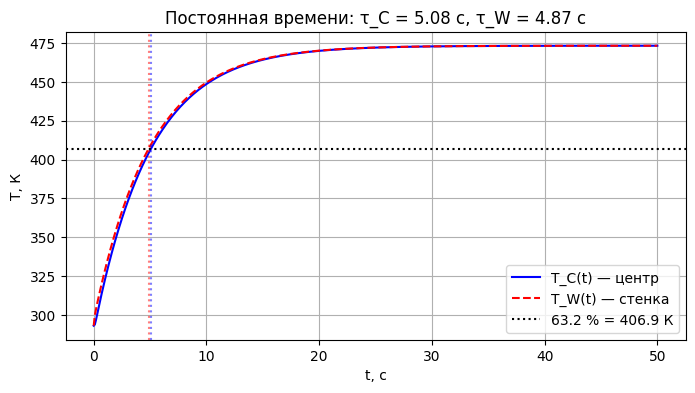

In [19]:
import numpy as np
import matplotlib.pyplot as plt

T0, TF = 293.15, 473.15
T_target = T0 + 0.632*(TF - T0)

d = np.loadtxt('RESULT_SIN_step.DAT', skiprows=1)
t, T_C, T_W = d[:,0], d[:,2], d[:,3]

# интерполяция для точного tau
tC = np.interp(T_target, T_C, t)
tW = np.interp(T_target, T_W, t)
print(f"tau_C = {tC:.3f} с")
print(f"tau_W = {tW:.3f} с")

plt.figure(figsize=(8,4))
plt.plot(t, T_C, 'b-', label='T_C(t) — центр')
plt.plot(t, T_W, 'r--', label='T_W(t) — стенка')
plt.axhline(T_target, color='k', ls=':', label='63.2 % = 406.9 К')
plt.axvline(tC, color='b', ls=':', alpha=0.5)
plt.axvline(tW, color='r', ls=':', alpha=0.5)
plt.xlabel('t, с'); plt.ylabel('T, К')
plt.legend(); plt.grid(True)
plt.title(f'Постоянная времени: τ_C = {tC:.2f} с, τ_W = {tW:.2f} с')
plt.savefig('tau_center.png', dpi=150)
plt.show()

  ω, рад/с        K_C    K_C, дБ     φ_C, °        K_W    K_W, дБ     φ_W, °
---------------------------------------------------------------------------
     0.100     0.8948      -0.97     -26.57     0.8952      -0.96     -25.42
  нет RESULT_om0.15.DAT
     0.200     0.7086      -2.99     -45.42     0.7089      -2.99     -43.10
     0.300     0.5563      -5.09     -57.36     0.5568      -5.09     -53.85
     0.500     0.3726      -8.57     -71.02     0.3736      -8.55     -65.20
     1.000     0.1965     -14.13     -84.45     0.1986     -14.04     -72.87
     3.000     0.0658     -23.64    -103.71     0.0717     -22.88     -69.50
  нет RESULT_om10.0.DAT
  нет RESULT_om30.0.DAT


/tmp/ipykernel_2345/48622540.py:46: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  c = 2/PERIOD * np.trapz(y*np.cos(om*tt), tt)
/tmp/ipykernel_2345/48622540.py:47: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  s = 2/PERIOD * np.trapz(y*np.sin(om*tt), tt)



Сохранено: afc.png
Сохранено: pfc.png

=== Частота среза ===
ωc ≈ 0.2007 рад/с
f_c ≈ 0.0319 Гц
τ = 1/ωc ≈ 4.9826 с
Сравнение: τ_скачок = 5.08 с, 1/ωc = 4.9826 с
Отклонение: 1.92 %
Сохранено: afc_with_wc.png

φ(ωc) ≈ -45.5° (ожидается −45°)
Сохранено: afc_compare.png
Сохранено: pfc_compare.png

=== Готово ===


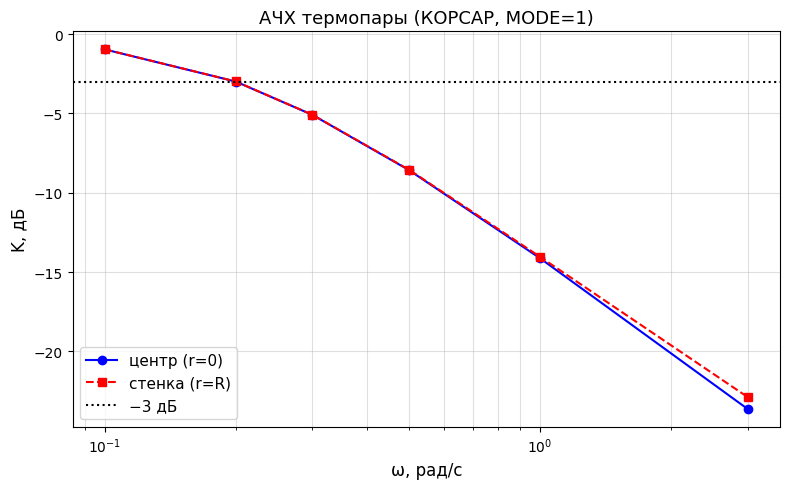

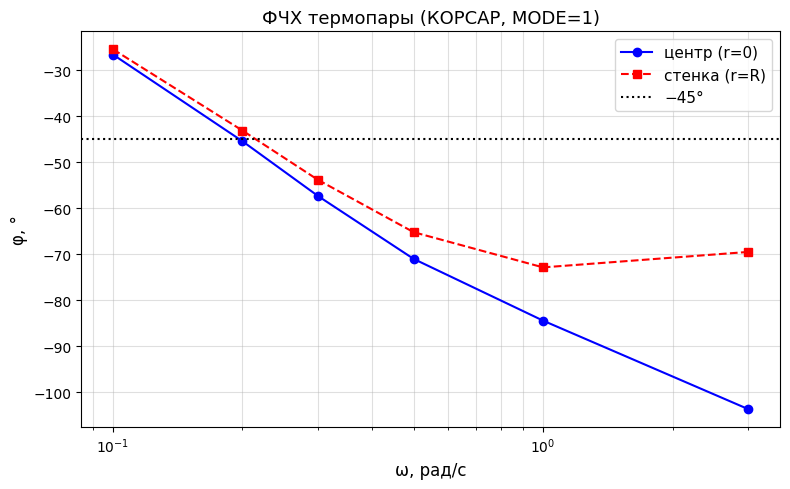

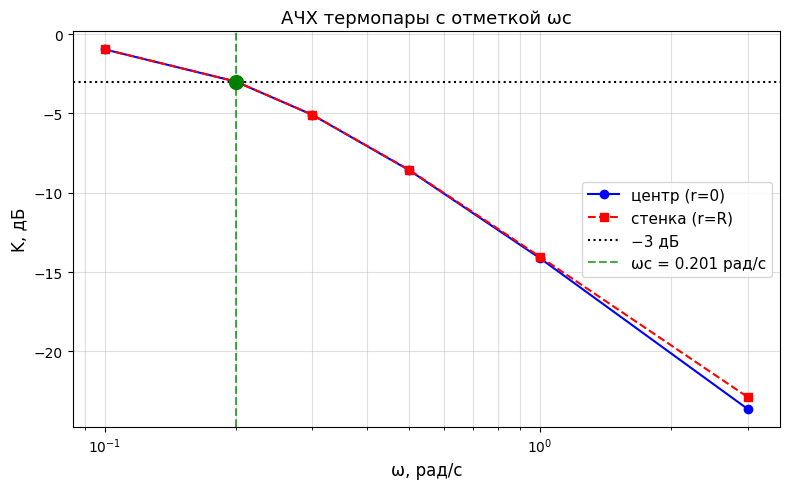

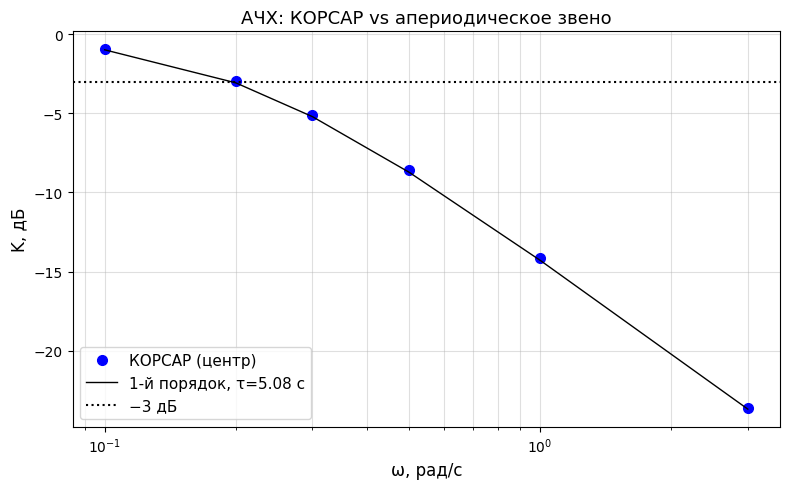

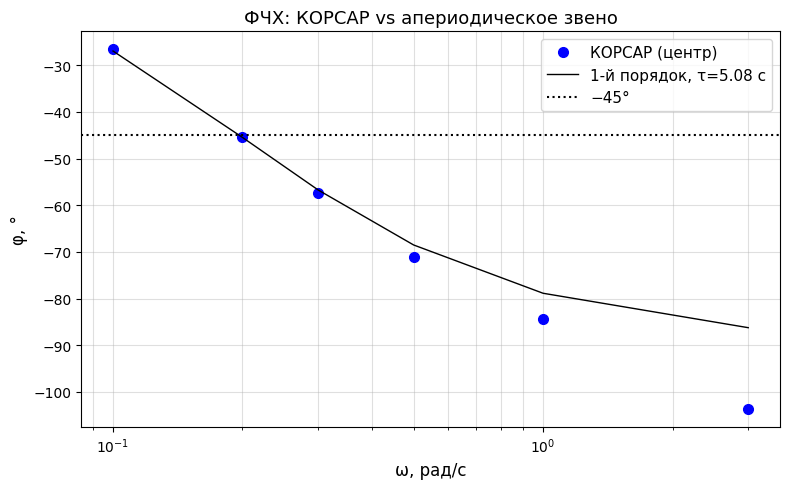

In [25]:
"""
Обработка гармонических прогонов КОРСАР (MODE=1) для построения АЧХ/ФЧХ.
Читает RESULT_om{ω}.DAT: TAU, T_ENV_IN, T_C, T_W, Q_surf.
Строит: afc.png (АЧХ), pfc.png (ФЧХ), находит ωc по -3 дБ.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import os

# ============================================================
# 1. Список частот (какие файлы есть в папке)
# ============================================================
omegas = [0.1, 0.15, 0.2, 0.3, 0.5, 1.0, 3.0, 10.0, 30.0]

# ============================================================
# 2. Функция обработки одного файла
# ============================================================
def process(fname, om):
    """
    Читает RESULT_om{ω}.DAT, берёт последние 3 периода,
    возвращает: K_C, K_W, phi_C, phi_W.
    """
    d = np.loadtxt(fname, skiprows=1)
    t, T_in, T_C, T_W = d[:,0], d[:,1], d[:,2], d[:,3]

    PERIOD = 2*np.pi/om
    t_end = t[-1]

    # --- Амплитуды по последним 3 периодам ---
    m3 = t > (t_end - 3*PERIOD)
    A_in = 0.5*(T_in[m3].max() - T_in[m3].min())   # ~90 К
    A_C  = 0.5*(T_C[m3].max()  - T_C[m3].min())
    A_W  = 0.5*(T_W[m3].max()  - T_W[m3].min())

    K_C = A_C / A_in
    K_W = A_W / A_in

    # --- Фаза по последнему периоду (интегралы Фурье) ---
    t0 = t_end - PERIOD
    mp = t > t0
    tt = t[mp]

    def coefs(y, tt, om):
        c = 2/PERIOD * np.trapz(y*np.cos(om*tt), tt)
        s = 2/PERIOD * np.trapz(y*np.sin(om*tt), tt)
        return c, s

    yin = T_in[mp] - T_in[mp].mean()
    yC  = T_C[mp]  - T_C[mp].mean()
    yW  = T_W[mp]  - T_W[mp].mean()

    ci, si = coefs(yin, tt, om)
    cC, sC = coefs(yC,  tt, om)
    cW, sW = coefs(yW,  tt, om)

    phi_in = np.arctan2(ci, si)
    phi_C  = np.arctan2(cC, sC)
    phi_W  = np.arctan2(cW, sW)

    def norm(d):
        return (d + 180) % 360 - 180

    dphi_C = norm((phi_C - phi_in)*180/np.pi)
    dphi_W = norm((phi_W - phi_in)*180/np.pi)

    return K_C, K_W, dphi_C, dphi_W

# ============================================================
# 3. Проход по всем файлам
# ============================================================
K_C_list, K_W_list = [], []
phi_C_list, phi_W_list = [], []
om_ok = []

print(f"{'ω, рад/с':>10} {'K_C':>10} {'K_C, дБ':>10} {'φ_C, °':>10} "
      f"{'K_W':>10} {'K_W, дБ':>10} {'φ_W, °':>10}")
print("-" * 75)

for om in omegas:
    fname = f'RESULT_om{om}.DAT'
    if not os.path.exists(fname):
        print(f"  нет {fname}")
        continue
    kC, kW, pC, pW = process(fname, om)
    K_C_list.append(kC); K_W_list.append(kW)
    phi_C_list.append(pC); phi_W_list.append(pW)
    om_ok.append(om)
    print(f"{om:>10.3f} {kC:>10.4f} {20*np.log10(kC):>10.2f} {pC:>10.2f} "
          f"{kW:>10.4f} {20*np.log10(kW):>10.2f} {pW:>10.2f}")

om_arr  = np.array(om_ok)
K_C_arr = np.array(K_C_list)
K_W_arr = np.array(K_W_list)
phi_C_arr = np.array(phi_C_list)
phi_W_arr = np.array(phi_W_list)

# ============================================================
# 4. АЧХ
# ============================================================
plt.figure(figsize=(8, 5))
plt.semilogx(om_arr, 20*np.log10(K_C_arr), 'o-', color='blue',
             label='центр (r=0)', markersize=6)
plt.semilogx(om_arr, 20*np.log10(K_W_arr), 's--', color='red',
             label='стенка (r=R)', markersize=6)
plt.axhline(-3, color='k', ls=':', label='−3 дБ')
plt.xlabel('ω, рад/с', fontsize=12)
plt.ylabel('K, дБ', fontsize=12)
plt.title('АЧХ термопары (КОРСАР, MODE=1)', fontsize=13)
plt.grid(True, which='both', alpha=0.4)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('afc.png', dpi=150)
print("\nСохранено: afc.png")

# ============================================================
# 5. ФЧХ
# ============================================================
plt.figure(figsize=(8, 5))
plt.semilogx(om_arr, phi_C_arr, 'o-', color='blue',
             label='центр (r=0)', markersize=6)
plt.semilogx(om_arr, phi_W_arr, 's--', color='red',
             label='стенка (r=R)', markersize=6)
plt.axhline(-45, color='k', ls=':', label='−45°')
plt.xlabel('ω, рад/с', fontsize=12)
plt.ylabel('φ, °', fontsize=12)
plt.title('ФЧХ термопары (КОРСАР, MODE=1)', fontsize=13)
plt.grid(True, which='both', alpha=0.4)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('pfc.png', dpi=150)
print("Сохранено: pfc.png")

# ============================================================
# 6. Частота среза ωc (по -3 дБ на АЧХ центра)
# ============================================================
K_target = 1/np.sqrt(2)   # 0.7071

# проверяем, что есть точки по обе стороны от K_target
if len(K_C_arr) < 2:
    print("Мало точек для определения ωc")
else:
    # лог-лог интерполяция
    logK = np.log(K_C_arr)
    logo = np.log(om_arr)
    f_interp = interp1d(logK, logo, fill_value='extrapolate')
    try:
        wc = np.exp(f_interp(np.log(K_target)))
        fc = wc / (2*np.pi)
        tau = 1/wc

        print(f"\n=== Частота среза ===")
        print(f"ωc ≈ {wc:.4f} рад/с")
        print(f"f_c ≈ {fc:.4f} Гц")
        print(f"τ = 1/ωc ≈ {tau:.4f} с")
        print(f"Сравнение: τ_скачок = 5.08 с, 1/ωc = {tau:.4f} с")
        print(f"Отклонение: {abs(tau - 5.08)/5.08*100:.2f} %")

        # отметка на АЧХ
        plt.figure(figsize=(8, 5))
        plt.semilogx(om_arr, 20*np.log10(K_C_arr), 'o-', color='blue',
                     label='центр (r=0)', markersize=6)
        plt.semilogx(om_arr, 20*np.log10(K_W_arr), 's--', color='red',
                     label='стенка (r=R)', markersize=6)
        plt.axhline(-3, color='k', ls=':', label='−3 дБ')
        plt.axvline(wc, color='green', ls='--', alpha=0.7,
                    label=f'ωc = {wc:.3f} рад/с')
        plt.scatter([wc], [-3], color='green', s=100, zorder=5)
        plt.xlabel('ω, рад/с', fontsize=12)
        plt.ylabel('K, дБ', fontsize=12)
        plt.title('АЧХ термопары с отметкой ωc', fontsize=13)
        plt.grid(True, which='both', alpha=0.4)
        plt.legend(fontsize=11)
        plt.tight_layout()
        plt.savefig('afc_with_wc.png', dpi=150)
        print("Сохранено: afc_with_wc.png")
    except Exception as e:
        print(f"Ошибка при поиске ωc: {e}")

# ============================================================
# 7. Проверка: φ(ωc) ≈ -45°
# ============================================================
try:
    phi_at_wc = np.interp(np.log(wc), np.log(om_arr), phi_C_arr)
    print(f"\nφ(ωc) ≈ {phi_at_wc:.1f}° (ожидается −45°)")
except Exception:
    pass

# ============================================================
# 8. Аналитическая проверка (для сравнения, не для отчёта)
# ============================================================
# Если хотите наложить теоретическую кривую 1-го порядка:
# K_an = 1/sqrt(1 + (ω·τ)²),  φ_an = -arctan(ω·τ),  τ = 5.08 с
tau_an = 5.08
K_an = 1/np.sqrt(1 + (om_arr*tau_an)**2)
phi_an = -np.arctan(om_arr*tau_an)*180/np.pi

plt.figure(figsize=(8, 5))
plt.semilogx(om_arr, 20*np.log10(K_C_arr), 'o', color='blue',
             label='КОРСАР (центр)', markersize=7)
plt.semilogx(om_arr, 20*np.log10(K_an), 'k-', lw=1,
             label=f'1-й порядок, τ={tau_an} с')
plt.axhline(-3, color='k', ls=':', label='−3 дБ')
plt.xlabel('ω, рад/с', fontsize=12)
plt.ylabel('K, дБ', fontsize=12)
plt.title('АЧХ: КОРСАР vs апериодическое звено', fontsize=13)
plt.grid(True, which='both', alpha=0.4)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('afc_compare.png', dpi=150)
print("Сохранено: afc_compare.png")

plt.figure(figsize=(8, 5))
plt.semilogx(om_arr, phi_C_arr, 'o', color='blue',
             label='КОРСАР (центр)', markersize=7)
plt.semilogx(om_arr, phi_an, 'k-', lw=1,
             label=f'1-й порядок, τ={tau_an} с')
plt.axhline(-45, color='k', ls=':', label='−45°')
plt.xlabel('ω, рад/с', fontsize=12)
plt.ylabel('φ, °', fontsize=12)
plt.title('ФЧХ: КОРСАР vs апериодическое звено', fontsize=13)
plt.grid(True, which='both', alpha=0.4)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('pfc_compare.png', dpi=150)
print("Сохранено: pfc_compare.png")

print("\n=== Готово ===")

Эталоны
[K-эталон] RESULT_THETA_step_K41.DAT  (K=41, DT=0.001)
  RESULT_THETA_step_K41.DAT         N= 501  n_cols=43  TAU[-1]=50  Fo[-1]=61.54  θ_C[0]=1  θ_C[-1]=4.43e-05

[DT-эталон] RESULT_THETA_step_DT5e-04.DAT  (K=21, DT=0.0005)
  RESULT_THETA_step_DT5e-04.DAT     N= 501  n_cols=23  TAU[-1]=50  Fo[-1]=61.54  θ_C[0]=1  θ_C[-1]=4.43e-05

Аналитика при Fo = 0.02: θ_C = 1.000000, θ_W = 0.985949

Сходимость по K  (DT = 0.001 фикс, эталон K = 41)
   K |    θ_C_num     θ_C_an |   ε_схемы(K)    ε_анал(K)
------------------------------------------------------------------------------
   5 |   0.999266   1.000000 |    9.818e-04    7.338e-04
  11 |   0.999291   1.000000 |    1.413e-04    7.088e-04
  21 |   0.999295   1.000000 |    2.830e-05    7.049e-04
  41 |   0.999296   1.000000 |    0.000e+00    7.039e-04

Сходимость по DT_MAX  (K = 21 фикс, эталон — K=21, DT=0.0005)
    DT_MAX |    θ_C_num     θ_C_an |  ε_схемы(DT)   ε_анал(DT)
-------------------------------------------------------------

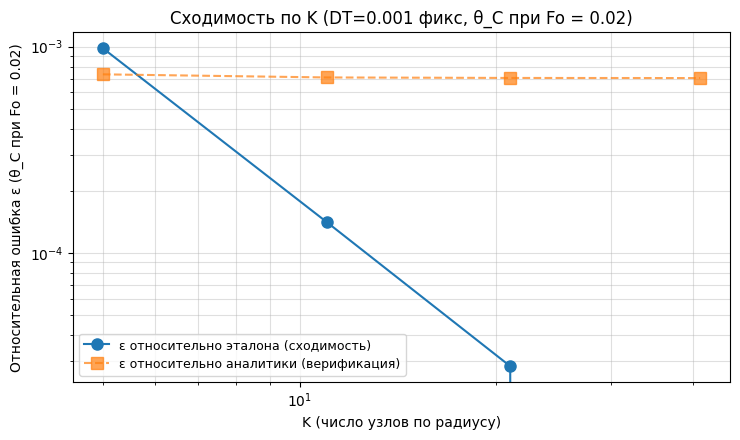


Сохранено: convergence_DT.png


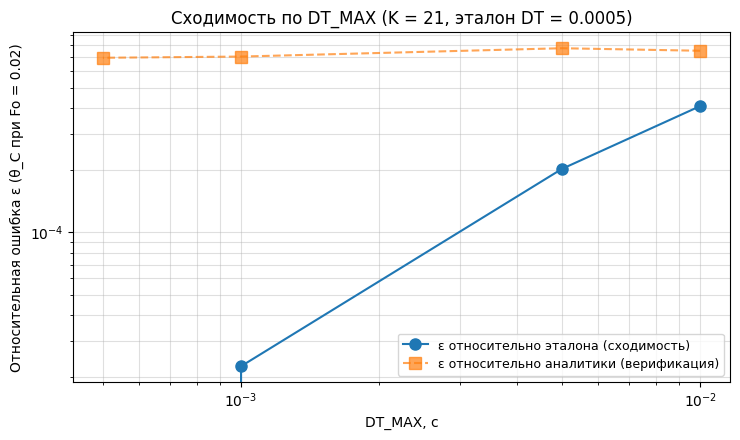


Оценка порядка сходимости
  По K:   d(log ε)/d(log K)  = -2.47  →  p_K  ≈ +2.47
  По DT:  d(log ε)/d(log DT) = +1.27  →  p_DT ≈ +1.27

Сохранено: convergence_K.csv
Сохранено: convergence_DT.csv

=== Готово ===


In [36]:
# -*- coding: utf-8 -*-
"""
Анализ сходимости КОРСАР по K_RAD и по DT_MAX.

A) K-серия:  K ∈ {5, 11, 21, 41},  DT = 1e-3 фикс.
   Эталон:  RESULT_THETA_step_K41.DAT  (K=41, DT=1e-3).

B) DT-серия: K = 21 фикс,  DT ∈ {1e-2, 5e-3, 1e-3, 5e-4}.
   Эталон:  RESULT_THETA_step_DT5e-04.DAT  (K=21, DT=5e-4).

Сравнение: max|Δθ| по всем Fo и всем r относительно своего эталона;
плюс θ_C(Fo=FO_CMP) для таблицы и ε_аналит (верификация по Бесселю).
"""

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0, j1
from scipy.optimize import brentq

# ============================================================
# 1. Параметры задачи
# ============================================================
R      = 0.0025
LAM    = 30.0
RHO    = 7800.0
C      = 500.0
ALPHA  = 1000.0
T0     = 293.15
TF     = 473.15
BI     = ALPHA * R / LAM

# ============================================================
# 2. Настройки серий и эталонов
# ============================================================
FO_CMP = 0.02

# --- Серия K: DT фиксирован на 1e-3 ---
K_list       = [5, 11, 21, 41]
K_REF        = 41
K_DT_FIXED   = 1e-3
REF_K_FILE   = f"RESULT_THETA_step_K{K_REF}.DAT"

# --- Серия DT: K фиксирован на 21, эталон DT = 5e-4 ---
K_FIXED      = 21
DT_list      = [1e-2, 5e-3, 1e-3, 5e-4]
DT_REF       = 5e-4
REF_DT_FILE  = "RESULT_THETA_step_DT5e-04.DAT"

# ============================================================
# 3. Аналитика (ряд Бесселя, бесконечный цилиндр, ГУ III)
# ============================================================
def find_mu_roots(Bi, N=200):
    roots = []
    n = 1
    while len(roots) < N:
        lo, hi = (n - 1.0) * np.pi + 1e-8, n * np.pi
        f_lo = lo * j1(lo) - Bi * j0(lo)
        f_hi = hi * j1(hi) - Bi * j0(hi)
        if f_lo * f_hi < 0:
            mu = brentq(lambda m: m * j1(m) - Bi * j0(m),
                        lo, hi, xtol=1e-14, rtol=1e-14)
            roots.append(mu)
        n += 1
    return np.array(roots)

MU     = find_mu_roots(BI, N=200)
A_COEF = 2.0 * BI / ((MU**2 + BI**2) * j0(MU))

def theta_analytic(eta, Fo, tol=1e-13):
    eta = np.atleast_1d(eta).astype(float)
    th = np.zeros_like(eta)
    for m, a in zip(MU, A_COEF):
        term = a * j0(m * eta) * np.exp(-(m**2) * Fo)
        th += term
        if np.max(np.abs(term)) < tol:
            break
    return th

# ============================================================
# 4. Загрузка RESULT_THETA_step_*.DAT
# ============================================================
def load_theta(fname, K_RAD, verbose=True):
    if not os.path.exists(fname):
        raise FileNotFoundError(fname)
    with open(fname, "r") as f:
        lines = [ln.rstrip("\n") for ln in f if ln.strip()]
    if not lines:
        raise ValueError(f"{fname}: пустой файл")

    start = 0
    try:
        float(lines[0].split()[0])
    except (ValueError, IndexError):
        start = 1

    n_cols = 2 + K_RAD
    tokens = []
    for ln in lines[start:]:
        tokens.extend(ln.split())

    n_rows = len(tokens) // n_cols
    if n_rows == 0:
        raise ValueError(
            f"{fname}: нет ни одной полной строки "
            f"(нужно {n_cols} чисел/строку, найдено {len(tokens)})"
        )
    if verbose and len(tokens) % n_cols:
        print(f"  [warn] {fname}: отброшено {len(tokens) % n_cols} "
              f"токенов в конце")

    data = np.array(tokens[:n_rows * n_cols], dtype=float).reshape(n_rows, n_cols)
    TAU, Fo, THETA = data[:, 0], data[:, 1], data[:, 2:2 + K_RAD]

    if verbose:
        print(f"  {os.path.basename(fname):32s}  "
              f"N={n_rows:4d}  n_cols={n_cols}  "
              f"TAU[-1]={TAU[-1]:.4g}  Fo[-1]={Fo[-1]:.4g}  "
              f"θ_C[0]={THETA[0, 0]:.4g}  θ_C[-1]={THETA[-1, 0]:.3g}")

    if abs(THETA[0, 0] - 1.0) > 0.5:
        print(f"  [warn] {fname}: θ_C[0] = {THETA[0,0]:.3g} — "
              f"ожидалось ≈ 1.0 при Fo=0")
    if Fo[-1] < Fo[0]:
        print(f"  [warn] {fname}: Fo[-1] < Fo[0] — вторая колонка не Fo")
    if np.any(np.abs(THETA) > 5.0):
        print(f"  [warn] {fname}: |θ| > 5 — возможно, это НЕ θ")

    return TAU, Fo, THETA

# ============================================================
# 5. Поиск файлов
# ============================================================
def find_K_file(k):
    for c in (f"RESULT_THETA_step_K{k}.DAT",
              f"RESULT_THETA_step_K{k}.dat"):
        if os.path.exists(c):
            return c
    return None

def find_DT_file(dt):
    cands = [
        f"RESULT_THETA_step_DT{dt:.0e}.DAT",
        f"RESULT_THETA_step_DT{dt:.1e}.DAT",
        f"RESULT_THETA_step_DT{dt:g}.DAT",
        f"RESULT_THETA_step_DT_{dt:.0e}.DAT",
        f"RESULT_THETA_step_DT_{dt:g}.DAT",
        f"RESULT_THETA_step_DT{dt:.0e}.dat",
        f"RESULT_THETA_step_DT_{dt:.0e}.dat",
    ]
    for c in cands:
        if os.path.exists(c):
            return c
    return None

# ============================================================
# 6. Сравнение варианта с эталоном
# ============================================================
def interp_to_grid(th_src, K_src, K_dst, r_max=R):
    r_src = np.linspace(0.0, r_max, K_src)
    r_dst = np.linspace(0.0, r_max, K_dst)
    return np.interp(r_dst, r_src, th_src)

def theta_at_Fo(Fo_arr, THETA, Fo_target):
    if Fo_target < Fo_arr.min() or Fo_target > Fo_arr.max():
        raise ValueError(f"Fo={Fo_target} вне [{Fo_arr.min():.4g}, {Fo_arr.max():.4g}]")
    return np.array([np.interp(Fo_target, Fo_arr, THETA[:, j])
                     for j in range(THETA.shape[1])])

def max_error_vs_ref(fname, K_var, ref_Fo, ref_THETA, K_ref):
    _, Fo, THETA = load_theta(fname, K_var, verbose=False)
    if Fo.size == 0:
        raise ValueError(f"{fname}: пустая Fo-сетка")

    ref_on_var = np.array([np.interp(Fo, ref_Fo, ref_THETA[:, j])
                           for j in range(ref_THETA.shape[1])]).T

    err = 0.0
    for i in range(Fo.size):
        th_var = THETA[i]
        if K_var != K_ref:
            th_var = interp_to_grid(th_var, K_var, K_ref)
        d = float(np.max(np.abs(th_var - ref_on_var[i])))
        if d > err:
            err = d

    th_cmp = theta_at_Fo(Fo, THETA, FO_CMP)
    return err, float(th_cmp[0])

# ============================================================
# 7. Загрузка эталонов
# ============================================================
print("=" * 78)
print("Эталоны")
print("=" * 78)

if not os.path.exists(REF_K_FILE):
    raise SystemExit(f"Нет файла эталона K-серии: {REF_K_FILE}")
print(f"[K-эталон] {REF_K_FILE}  (K={K_REF}, DT={K_DT_FIXED:g})")
TAU_REF_K, Fo_REF_K, THETA_REF_K = load_theta(REF_K_FILE, K_REF, verbose=True)

if not os.path.exists(REF_DT_FILE):
    raise SystemExit(
        f"Нет файла эталона DT-серии: {REF_DT_FILE}\n"
        f"DT-серию нужно считать при K={K_FIXED} и DT={DT_REF:g}."
    )
print(f"\n[DT-эталон] {REF_DT_FILE}  (K={K_FIXED}, DT={DT_REF:g})")
TAU_REF_DT, Fo_REF_DT, THETA_REF_DT = load_theta(REF_DT_FILE, K_FIXED, verbose=True)

print()
print(f"Аналитика при Fo = {FO_CMP}: "
      f"θ_C = {float(theta_analytic(np.array([0.0]), FO_CMP)[0]):.6f}, "
      f"θ_W = {float(theta_analytic(np.array([1.0]), FO_CMP)[0]):.6f}")

# ============================================================
# 8. Серия K
# ============================================================
th_C_an = float(theta_analytic(np.array([0.0]), FO_CMP)[0])
th_W_an = float(theta_analytic(np.array([1.0]), FO_CMP)[0])

K_ok, eps_scheme_K, eps_analytic_K = [], [], []

print()
print("=" * 78)
print(f"Сходимость по K  (DT = {K_DT_FIXED:g} фикс, эталон K = {K_REF})")
print("=" * 78)
print(f"{'K':>4} | {'θ_C_num':>10} {'θ_C_an':>10} | "
      f"{'ε_схемы(K)':>12} {'ε_анал(K)':>12}")
print("-" * 78)

for k in K_list:
    fname = find_K_file(k)
    if fname is None:
        print(f"{k:>4} |  нет файла RESULT_THETA_step_K{k}.DAT")
        continue
    try:
        err, th_C_num = max_error_vs_ref(
            fname, k, Fo_REF_K, THETA_REF_K, K_REF)
    except Exception as e:
        print(f"{k:>4} |  ошибка: {e}")
        continue

    eps_an = abs(th_C_num - th_C_an) / max(abs(th_C_an), 1e-12)
    print(f"{k:>4} | {th_C_num:>10.6f} {th_C_an:>10.6f} | "
          f"{err:>12.3e} {eps_an:>12.3e}")
    K_ok.append(k)
    eps_scheme_K.append(err)
    eps_analytic_K.append(eps_an)

# ============================================================
# 9. Серия DT (K = K_FIXED, эталон = K_FIXED, DT_REF)
# ============================================================
DT_ok, eps_scheme_DT, eps_analytic_DT = [], [], []

print()
print("=" * 78)
print(f"Сходимость по DT_MAX  (K = {K_FIXED} фикс, эталон — "
      f"K={K_FIXED}, DT={DT_REF:g})")
print("=" * 78)
print(f"{'DT_MAX':>10} | {'θ_C_num':>10} {'θ_C_an':>10} | "
      f"{'ε_схемы(DT)':>12} {'ε_анал(DT)':>12}")
print("-" * 78)

for dt in DT_list:
    fname = find_DT_file(dt)
    if fname is None:
        print(f"{dt:>10.0e} |  нет файла для DT={dt:g}")
        continue
    try:
        err, th_C_num = max_error_vs_ref(
            fname, K_FIXED, Fo_REF_DT, THETA_REF_DT, K_FIXED)
    except Exception as e:
        print(f"{dt:>10.0e} |  ошибка: {e}")
        continue

    eps_an = abs(th_C_num - th_C_an) / max(abs(th_C_an), 1e-12)
    print(f"{dt:>10.0e} | {th_C_num:>10.6f} {th_C_an:>10.6f} | "
          f"{err:>12.3e} {eps_an:>12.3e}")
    DT_ok.append(dt)
    eps_scheme_DT.append(err)
    eps_analytic_DT.append(eps_an)

# ============================================================
# 10. Диагностика Fo-сеток
# ============================================================
print()
print("=" * 78)
print("Диагностика Fo-сеток")
print("=" * 78)

print(f"  K-серия (DT={K_DT_FIXED:g} фикс):")
for k in K_list:
    f = find_K_file(k)
    if f is None:
        continue
    try:
        _, Fo, _ = load_theta(f, k, verbose=False)
        print(f"    {os.path.basename(f):32s}  N={len(Fo):4d}  "
              f"dFo={Fo[1]-Fo[0]:.4g}  Fo[-1]={Fo[-1]:.4g}")
    except Exception as e:
        print(f"    {os.path.basename(f):32s}  ERROR: {e}")

print(f"\n  DT-серия (K={K_FIXED} фикс, эталон DT={DT_REF:g}):")
for dt in [DT_REF] + DT_list:
    f = find_DT_file(dt)
    if f is None:
        continue
    try:
        _, Fo, _ = load_theta(f, K_FIXED, verbose=False)
        print(f"    {os.path.basename(f):32s}  N={len(Fo):4d}  "
              f"dFo={Fo[1]-Fo[0]:.4g}  Fo[-1]={Fo[-1]:.4g}")
    except Exception as e:
        print(f"    {os.path.basename(f):32s}  ERROR: {e}")

# ============================================================
# 11. Графики
# ============================================================
def plot_series(x, e_s, e_a, xlabel, title, fname):
    plt.figure(figsize=(7.5, 4.5))
    if len(x) >= 2:
        plt.loglog(x, e_s, "o-", markersize=8,
                   label="ε относительно эталона (сходимость)")
        plt.loglog(x, e_a, "s--", markersize=8, alpha=0.7,
                   label="ε относительно аналитики (верификация)")
        plt.xlabel(xlabel)
        plt.ylabel(f"Относительная ошибка ε (θ_C при Fo = {FO_CMP})")
        plt.title(title)
        plt.grid(True, which="both", alpha=0.4)
        plt.legend(fontsize=9)
        plt.tight_layout()
        plt.savefig(fname, dpi=140)
        print(f"\nСохранено: {fname}")
        plt.show()
        plt.close()
    else:
        print(f"\n[{fname}] мало точек для графика")

if len(K_ok) >= 2:
    plot_series(K_ok, eps_scheme_K, eps_analytic_K,
                xlabel="K (число узлов по радиусу)",
                title=f"Сходимость по K (DT={K_DT_FIXED:g} фикс, "
                      f"θ_C при Fo = {FO_CMP})",
                fname="convergence_K.png")

if len(DT_ok) >= 2:
    plot_series(DT_ok, eps_scheme_DT, eps_analytic_DT,
                xlabel="DT_MAX, с",
                title=f"Сходимость по DT_MAX (K = {K_FIXED}, "
                      f"эталон DT = {DT_REF:g})",
                fname="convergence_DT.png")

# ============================================================
# 12. Порядок сходимости
# ============================================================
def slope(x, y):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    m = (x > 0) & (y > 0)
    if m.sum() < 2:
        return np.nan
    return np.polyfit(np.log(x[m]), np.log(y[m]), 1)[0]

print()
print("=" * 78)
print("Оценка порядка сходимости")
print("=" * 78)

if len(K_ok) >= 2:
    sK = slope(K_ok, eps_scheme_K)
    print(f"  По K:   d(log ε)/d(log K)  = {sK:+.2f}  →  p_K  ≈ {-sK:+.2f}")

if len(DT_ok) >= 2:
    sDT = slope(DT_ok, eps_scheme_DT)
    print(f"  По DT:  d(log ε)/d(log DT) = {sDT:+.2f}  →  p_DT ≈ {sDT:+.2f}")

# ============================================================
# 13. CSV
# ============================================================
with open("convergence_K.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["K", "eps_scheme", "eps_analytic"])
    for k, es, ea in zip(K_ok, eps_scheme_K, eps_analytic_K):
        w.writerow([k, f"{es:.6e}", f"{ea:.6e}"])
print("\nСохранено: convergence_K.csv")

with open("convergence_DT.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["DT_MAX", "eps_scheme", "eps_analytic"])
    for dt, es, ea in zip(DT_ok, eps_scheme_DT, eps_analytic_DT):
        w.writerow([f"{dt:.6e}", f"{es:.6e}", f"{ea:.6e}"])
print("Сохранено: convergence_DT.csv")

print("\n=== Готово ===")